# Метод ближайших соседей. Решающие деревья

## 0. Импорт пакетов, загрузка данных

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42

In [3]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-{color}.csv"

def load_wine(color="red") -> pd.DataFrame:
    url = URL.format(color=color)
    try:
        return pd.read_csv(url, sep=";")
    except Exception as e:
        print(f"Источник недоступен ({type(e).__name__}): {url}")

df_raw = load_wine()

# Сразу убираем дубликаты ДО разбиения
df = df_raw.drop_duplicates()
features = [c for c in df.columns if c != "quality"]

print(f"было {len(df_raw)} наблюдений, после удаления дубликатов {len(df)}")
print(f"признаков: {len(features)}")

было 1599 наблюдений, после удаления дубликатов 1359
признаков: 11


## 1. Валидационная выборка

### 1.1 Зачем она нужна?

В прошлый раз параметр регуляризации подбирался по минимуму ошибки на тестовой выборке.
Формально модель теста не видела, но решение о выборе гиперпараметров принималось по нему —
значит, тест фактически участвовал в обучении.

Чтобы этого не происходило, выборка делится на три части:

$$X = X_{\text{train}} \sqcup X_{\text{val}} \sqcup X_{\text{test}}$$

* **train** — настройка параметров модели;
* **validation** — выбор гиперпараметров и сравнение моделей между собой;
* **test** — однократная финальная оценка, после которой ничего не меняется.

In [4]:
from sklearn.model_selection import train_test_split

X, y = df[features], df["quality"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=RANDOM_STATE)

print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)}")

train 815 | val 272 | test 272


### 1.2 Насколько точна сама оценка

Прежде чем сравнивать модели, обучим одну и ту же линейную регрессию на 40 разных разбиениях обучающей части (тест не трогаем).

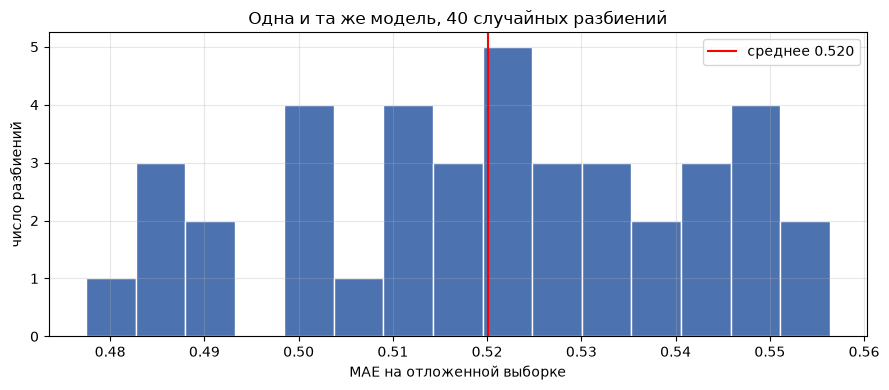

MAE = 0.5201 ± 0.0207


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

scores = []
for seed in range(40):
    Xa, Xb, ya, yb = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=seed)
    scores.append(mean_absolute_error(yb, LinearRegression().fit(Xa, ya).predict(Xb)))
scores = np.array(scores)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(scores, bins=15, color="#4C72B0", edgecolor="white")
ax.axvline(scores.mean(), color="red", lw=1.5, label=f"среднее {scores.mean():.3f}")
ax.set_xlabel("MAE на отложенной выборке")
ax.set_ylabel("число разбиений")
ax.set_title("Одна и та же модель, 40 случайных разбиений")
ax.legend()
plt.tight_layout(); plt.show()

print(f"MAE = {scores.mean():.4f} ± {scores.std():.4f}")

Разброс оценки составляет около 0.021. Это масштаб шума: разница в MAE меньше
этой величины сама по себе ничего не значит — она целиком объясняется тем,
какие объекты попали в отложенную часть.

В прошлый раз Ridge обогнал линейную регрессию и был назван лучшей моделью.
Однако перевес, который получился, был в пределах шума измерения, то есть вывод был не очень корректен.

### 1.3 Кросс-валидация

Вместо одного разбиения делим обучающую выборку на $k$ частей, каждая по очереди выступает валидационной,
результаты усредняются. Так используются все данные, и появляется оценка разброса случайного разбиения.

<center>
<img src="https://global.discourse-cdn.com/dlai/original/3X/a/3/a3ed2de61c2b4fa00f1b7e939753e1a7e181afb0.png" width="50%" align="center">
</center>

In [6]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv = -cross_val_score(LinearRegression(), X_train_full, y_train_full, cv=kf,
                      scoring="neg_mean_absolute_error")
print("по фолдам:", np.round(cv, 4))
print(f"CV MAE = {cv.mean():.4f} ± {cv.std():.4f}")

по фолдам: [0.5425 0.5124 0.5337 0.5044 0.4945]
CV MAE = 0.5175 ± 0.0180


Дальше для быстрых сравнений используем валидационную выборку, а итоговые модели сверяем
кросс-валидацией — она устойчивее, но важно помнить, что считается она в $k$ раз дольше.

Опорные значения в этот раз:

In [7]:
baseline_mae = mean_absolute_error(y_val, np.full(len(y_val), y_train.median()))
linear_mae = mean_absolute_error(y_val, LinearRegression().fit(X_train, y_train).predict(X_val))

print(f"константа (медиана train): val MAE {baseline_mae:.4f}")
print(f"линейная регрессия:        val MAE {linear_mae:.4f}")

константа (медиана train): val MAE 0.6949
линейная регрессия:        val MAE 0.5370


## 2. Метод k ближайших соседей

### 2.1 Модель

У kNN нет обучения в обычном смысле: модель запоминает выборку, а вся работа происходит
при предсказании. Для объекта $\mathbf{x}$ находятся $k$ ближайших обучающих объектов
$N_k(\mathbf{x})$, и ответ усредняется:

$$\hat{y}(\mathbf{x}) = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})} y_i.$$

Близость задаётся метрикой расстояния, обычно это расстояние Минковского
с выбранным параметром $c \ge 1$:

$$\rho(\mathbf{x}, \mathbf{x}') = \left(\sum_{j=1}^{p}|x_j - x'_j|^c\right)^{1/c},$$

где $p$ — число признаков. При $c = 2$ получается евклидово расстояние, при $c = 1$ — манхэттенское.

В модели нет ни обучаемых параметров, ни функции потерь — предположение модели в том, что похожие
по признакам объекты имеют похожую целевую переменную, это гипотеза компактности.

Обучим kNN, по умолчанию используется евклидово расстояние.

In [8]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_raw = KNeighborsRegressor(n_neighbors=5).fit(X_train, y_train)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)).fit(X_train, y_train)

print(f"kNN k=5 на сырых признаках:  val MAE {mean_absolute_error(y_val, knn_raw.predict(X_val)):.4f}")
print(f"kNN k=5 со стандартизацией:  val MAE {mean_absolute_error(y_val, knn_scaled.predict(X_val)):.4f}")
print(f"константа:                   val MAE {baseline_mae:.4f}")

kNN k=5 на сырых признаках:  val MAE 0.6184
kNN k=5 со стандартизацией:  val MAE 0.5588
константа:                   val MAE 0.6949


### 2.2 Почему масштаб признаков решает всё

Сырой вариант заметно хуже стандартизованного, хотя признаки те же. Причина в том,
что в сумме квадратов разностей признаки с большими числовыми значениями дают
несопоставимо больший вклад. Посмотрим на долю каждого признака в квадрате расстояния.

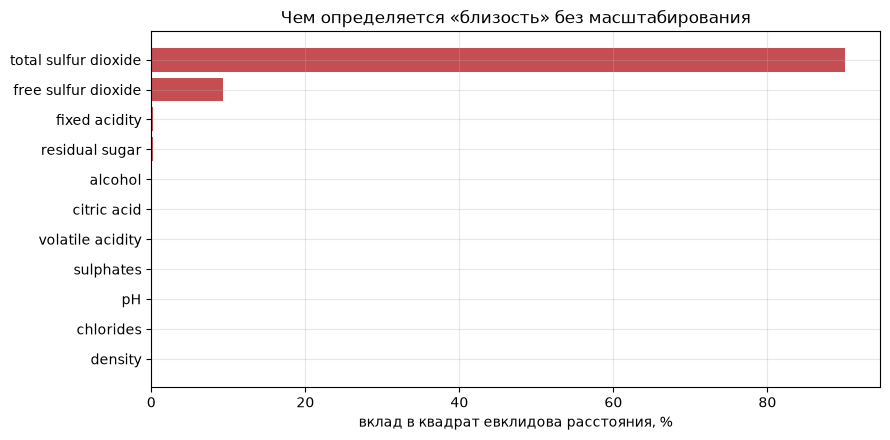

total sulfur dioxide    90.12
free sulfur dioxide      9.34
fixed acidity            0.26
residual sugar           0.17


In [9]:
var = X_train.var(ddof=0)
share = (var / var.sum()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(share.index[::-1], (share * 100)[::-1], color="#C44E52")
ax.set_xlabel("вклад в квадрат евклидова расстояния, %")
ax.set_title("Чем определяется «близость» без масштабирования")
plt.tight_layout(); 
plt.show()

print((share * 100).round(2).head(4).to_string())

Два признака из одиннадцати забирают 99.5% расстояния, причём это концентрации SO₂,
а не алкоголь с летучей кислотностью, которые связаны с оценкой сильнее всего.
Сырой kNN фактически игнорирует девять признаков.

После стандартизации $z_j = (x_j - \bar{x}_j) / \hat{\sigma}_j$ все признаки вносят
сопоставимый вклад. Для kNN, в отличие от линейной регрессии, это условие работоспособности.

In [10]:
for k in (5, 20):
    raw = mean_absolute_error(y_val, KNeighborsRegressor(k).fit(X_train, y_train).predict(X_val))
    scl = mean_absolute_error(y_val, make_pipeline(StandardScaler(), KNeighborsRegressor(k))
                              .fit(X_train, y_train).predict(X_val))
    print(f"k={k:2d}:  сырые {raw:.4f}   стандартизованные {scl:.4f}   выигрыш {raw - scl:+.4f}")

k= 5:  сырые 0.6184   стандартизованные 0.5588   выигрыш +0.0596
k=20:  сырые 0.6471   стандартизованные 0.5629   выигрыш +0.0842


### 2.3 Параметр k

$k$ управляет сложностью модели.

In [11]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 75, 100, 200, len(X_train)]
rows = []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(k)).fit(X_train, y_train)
    rows.append({"k": k,
                 "train MAE": mean_absolute_error(y_train, m.predict(X_train)),
                 "val MAE": mean_absolute_error(y_val, m.predict(X_val))})
knn_curve = pd.DataFrame(rows).set_index("k")
knn_curve

,train MAE,val MAE
k,,
1,0.0000,0.6103
2,0.2822,0.5680
3,0.3534,0.5674
5,0.4304,0.5588
10,0.4728,0.5625
15,0.4891,0.5713
20,0.5036,0.5629
30,0.5157,0.5646
50,0.5267,0.5608


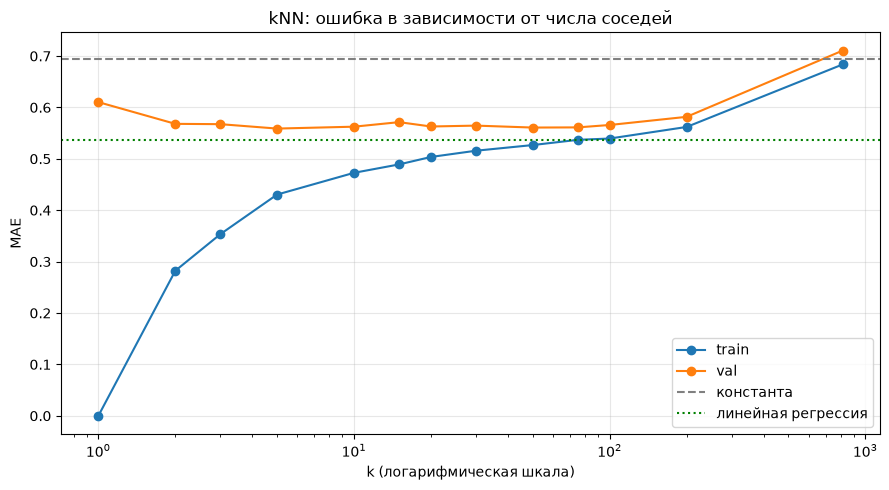

лучшее k по валидации: 5, val MAE 0.5588


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(knn_curve.index, knn_curve["train MAE"], "o-", label="train")
ax.plot(knn_curve.index, knn_curve["val MAE"], "o-", label="val")
ax.axhline(baseline_mae, color="gray", ls="--", label="константа")
ax.axhline(linear_mae, color="green", ls=":", label="линейная регрессия")
ax.set_xscale("log")
ax.set_xlabel("k (логарифмическая шкала)")
ax.set_ylabel("MAE")
ax.set_title("kNN: ошибка в зависимости от числа соседей")
ax.legend()
plt.tight_layout(); plt.show()

best_k = int(knn_curve["val MAE"].idxmin())
print(f"лучшее k по валидации: {best_k}, val MAE {knn_curve['val MAE'].min():.4f}")

При $k = 1$ ошибка на обучающей выборке равна нулю: ближайший сосед объекта — он сам.
Модель воспроизводит обучающие данные идеально, а на валидации проигрывает всем
промежуточным значениям $k$. Это самая наглядная демонстрация переобучения: никакой подгонки
коэффициентов нет, модель просто хранит таблицу.

При $k = n_{\text{train}}$ в соседи попадает вся выборка, и предсказание становится
её средним — то есть константной моделью с прошлого занятия. Значение на кривой при этом
чуть выше нашей опорной константы, потому что опорная использует медиану,
оптимальную для MAE, а kNN усредняет.

Так что $k$ непрерывно переводит модель от запоминания к полному игнорированию признаков.

### 2.4 Проклятие размерности

Линейной регрессии все 11 признаков помогали улучшать прогнозы. Проверим, так ли это для kNN.

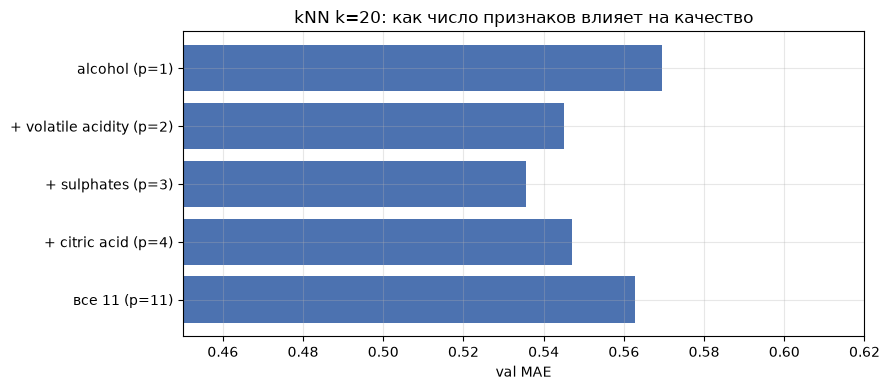

,val MAE
alcohol (p=1),0.5695
+ volatile acidity (p=2),0.5450
+ sulphates (p=3),0.5357
+ citric acid (p=4),0.5471
все 11 (p=11),0.5629


In [13]:
subsets = {
    "alcohol": ["alcohol"],
    "+ volatile acidity": ["alcohol", "volatile acidity"],
    "+ sulphates": ["alcohol", "volatile acidity", "sulphates"],
    "+ citric acid": ["alcohol", "volatile acidity", "sulphates", "citric acid"],
    "все 11": features,
}

res = {}
for name, cols in subsets.items():
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(20)).fit(X_train[cols], y_train)
    res[f"{name} (p={len(cols)})"] = mean_absolute_error(y_val, m.predict(X_val[cols]))

fig, ax = plt.subplots(figsize=(9, 4))
s = pd.Series(res)
ax.barh(s.index[::-1], s.values[::-1], color="#4C72B0")
ax.set_xlim(0.45, 0.62)
ax.set_xlabel("val MAE")
ax.set_title("kNN k=20: как число признаков влияет на качество")
plt.tight_layout(); plt.show()

pd.Series(res).round(4).to_frame("val MAE")

Лучший результат — на трёх признаках (0.536), все одиннадцать дают 0.563.
Для kNN добавление признаков может вредить, и вот почему: с ростом размерности
объём пространства растёт экспоненциально,
а число наблюдений нет. Точки оказываются далеко друг от друга, расстояния между всеми
парами становятся примерно одинаковыми, и «ближайший сосед» перестаёт быть похожим объектом.
Каждый неинформативный признак добавляет в метрику шум, который нечем взвесить:
евклидово расстояние считает все признаки равноправными, тогда как линейная регрессия
подбирает веса и может занулить бесполезный признак.

### 2.5 Утечка данных и ёмкость модели

На прошлом занятии мы видели, что дубликаты завышают качество тем сильнее, чем гибче модель.
kNN с $k=1$ — предельный случай: он находит точную копию объекта и выдаёт её метку.

In [14]:
Xd, yd = df_raw[features], df_raw["quality"]          # с дубликатами
Xa, Xb, ya, yb = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)
Xc, Xe, yc, ye = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

for k in (1, 5, 30):
    with_dup = mean_absolute_error(yb, make_pipeline(StandardScaler(), KNeighborsRegressor(k))
                                   .fit(Xa, ya).predict(Xb))
    without = mean_absolute_error(ye, make_pipeline(StandardScaler(), KNeighborsRegressor(k))
                                  .fit(Xc, yc).predict(Xe))
    print(f"k={k:2d}:  с дубликатами {with_dup:.4f}   без {without:.4f}   занижение MAE {without - with_dup:+.4f}")

k= 1:  с дубликатами 0.4344   без 0.5331   занижение MAE +0.0987
k= 5:  с дубликатами 0.5056   без 0.5397   занижение MAE +0.0341
k=30:  с дубликатами 0.5274   без 0.5238   занижение MAE -0.0036


При $k=1$ занижение около 0.10 — больше, чем у полиномиальной регрессии в прошлый раз.
При $k=5$ оно втрое меньше, а при $k=30$ исчезает совсем: усреднение по тридцати соседям
размывает вклад найденного двойника, и запоминать отдельные объекты модель уже не способна.
Та же закономерность, что и в прошлый раз, — утечка опасна ровно настолько,
насколько модель умеет запоминать. Но само собой утечки в принципе допускать нельзя!

### 2.6 Взвешивание соседей

До сих пор все $k$ соседей влияли на ответ одинаково. Но среди них один может быть
почти копией объекта, а $k$-й — уже довольно далёким. Естественно дать близким
соседям больший вес:

$$\hat{y}(\mathbf{x}) = \frac{\sum_{i \in N_k(\mathbf{x})} w_i\, y_i}{\sum_{i \in N_k(\mathbf{x})} w_i},
\qquad w_i = \frac{1}{\rho(\mathbf{x}, \mathbf{x}_i)}.$$

При $w_i \equiv 1$ получается прежняя формула (`weights="uniform"`), при обратном
расстоянии — `weights="distance"`. Знаменатель нужен, чтобы веса в сумме давали единицу:
иначе предсказание зависело бы от абсолютного масштаба расстояний.

In [15]:
rows = []
for k in (1, 2, 3, 5, 10, 20, 30, 50, 100, 200):
    out = {"k": k}
    for w in ("uniform", "distance"):
        m = make_pipeline(StandardScaler(), KNeighborsRegressor(k, weights=w)).fit(X_train, y_train)
        out[f"train {w}"] = mean_absolute_error(y_train, m.predict(X_train))
        out[f"val {w}"] = mean_absolute_error(y_val, m.predict(X_val))
    rows.append(out)

weights_curve = pd.DataFrame(rows).set_index("k")
weights_curve["выигрыш на val"] = weights_curve["val uniform"] - weights_curve["val distance"]
weights_curve.round(4)

,train uniform,val uniform,train distance,val distance,выигрыш на val
k,,,,,
1,0.0000,0.6103,0.0,0.6103,0.0000
2,0.2822,0.5680,0.0,0.5676,0.0004
3,0.3534,0.5674,0.0,0.5615,0.0059
5,0.4304,0.5588,0.0,0.5498,0.0091
10,0.4728,0.5625,0.0,0.5557,0.0068
20,0.5036,0.5629,0.0,0.5566,0.0063
30,0.5157,0.5646,0.0,0.5583,0.0063
50,0.5267,0.5608,0.0,0.5561,0.0047
100,0.5394,0.5658,0.0,0.5610,0.0048


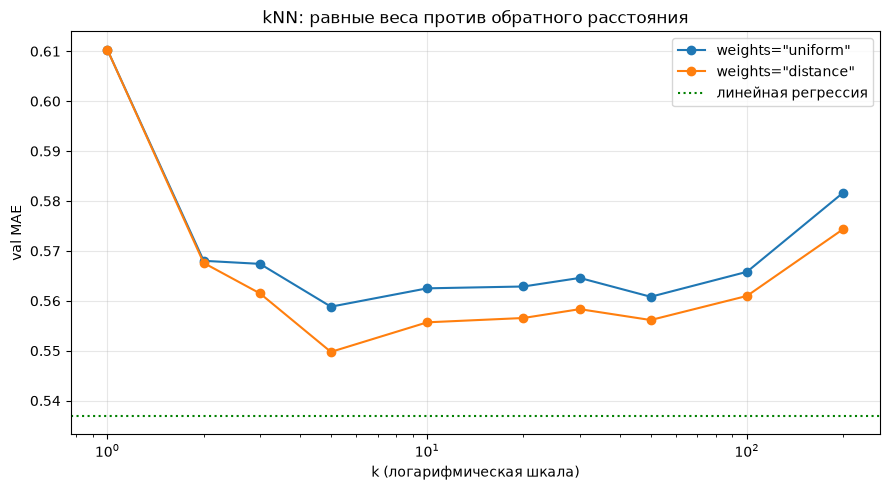

uniform  : лучшее k =   5, val MAE 0.5588
distance : лучшее k =   5, val MAE 0.5498


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(weights_curve.index, weights_curve["val uniform"], "o-", label='weights="uniform"')
ax.plot(weights_curve.index, weights_curve["val distance"], "o-", label='weights="distance"')
ax.axhline(linear_mae, color="green", ls=":", label="линейная регрессия")
ax.set_xscale("log")
ax.set_xlabel("k (логарифмическая шкала)")
ax.set_ylabel("val MAE")
ax.set_title("kNN: равные веса против обратного расстояния")
ax.legend()
plt.tight_layout(); plt.show()

for w in ("uniform", "distance"):
    col = f"val {w}"
    print(f'{w:9s}: лучшее k = {weights_curve[col].idxmin():3d}, val MAE {weights_curve[col].min():.4f}')

Взвешивание помогает при любом $k > 1$: кривая с весами идёт ниже на всём диапазоне.
При $k = 1$ оба варианта совпадают: взвешивать нечего, сосед один.

Про размер выигрыша стоит сказать прямо: он лежит между 0.0004 и 0.009, то есть
сам по себе меньше шума разбиения из раздела 1.2. Доверия ему добавляет не
величина, а то, что знак одинаков во всех девяти случаях.

Содержательно взвешивание ослабляет вред от далёких соседей. При равных весах
двухсотый сосед влияет на ответ ровно так же, как первый, хотя находится в разы дальше;
при обратном расстоянии его вклад оказывается мал. Поэтому и выигрыш сохраняется
при больших $k$: лишние соседи перестают влиять на предсказание.

А вот столбец с ошибкой на обучающей выборке стоит рассмотреть отдельно.

In [17]:
m = make_pipeline(StandardScaler(), KNeighborsRegressor(50, weights="distance")).fit(X_train, y_train)
pred_train = m.predict(X_train)

print(f"k=50, weights='distance': train MAE = {mean_absolute_error(y_train, pred_train):.10f}")
print(f"предсказания совпадают с метками точно: {np.allclose(pred_train, y_train.values)}")

# почему: обучающий объект сам входит в число своих соседей, расстояние до него равно нулю
scaler = StandardScaler().fit(X_train)
knn = KNeighborsRegressor(3).fit(scaler.transform(X_train), y_train)
dist, _ = knn.kneighbors(scaler.transform(X_train.iloc[[0]]))
print(f"\nрасстояния до трёх ближайших соседей обучающего объекта: {np.round(dist.ravel(), 4)}")

k=50, weights='distance': train MAE = 0.0000000000
предсказания совпадают с метками точно: True

расстояния до трёх ближайших соседей обучающего объекта: [0.     1.1179 1.3734]


При `weights="distance"` ошибка на обучающей выборке равна нулю **при любом** $k$, а не
только при $k = 1$. Причина в нулевом расстоянии: обучающий объект входит в число своих
соседей, его вес обращается в бесконечность, и все остальные соседи перестают играть роль.
В реализации это обрабатывается отдельным случаем — объекту с нулевым расстоянием
отдаётся весь вес.

Для взвешенного kNN обучающая ошибка неинформативна в принципе.
Она равна нулю и у разумной модели с $k = 50$, и у заведомо переобученной с $k = 1$,
поэтому судить о качестве можно только по отложенной выборке.

## 3. Решающие деревья

### 3.1 Устройство

Дерево разбивает пространство признаков на прямоугольные области условиями вида
$x_j \le t$ и в каждой области предсказывает константу — среднее ответов попавших туда
обучающих объектов.

Разбиение подбирается жадно. Для узла с объектами $R$ перебираются все признаки
и все пороги; качество разбиения на $R_{\text{left}}$ и $R_{\text{right}}$ оценивается
взвешенной суммой внутренних дисперсий:

$$Q(j, t) = \frac{|R_{\text{left}}|}{|R|}\,\mathrm{Var}(R_{\text{left}})
+ \frac{|R_{\text{right}}|}{|R|}\,\mathrm{Var}(R_{\text{right}}) \;\longrightarrow\; \min_{j,\,t}.$$

Выбирается пара (признак, порог), максимально снижающая $Q$ относительно дисперсии в узле.
Посчитаем это вручную для корня.

In [18]:
def weighted_var(col, thr, Xs=X_train, ys=y_train, min_side=5):
    mask = Xs[col].values <= thr
    if mask.sum() < min_side or (~mask).sum() < min_side:
        return np.nan
    left, right = ys.values[mask], ys.values[~mask]
    return (len(left) * left.var() + len(right) * right.var()) / len(ys)

var_root = y_train.values.var()
print(f"дисперсия в корне: {var_root:.5f}\n")

for thr in (9.5, 10.0, 10.3, 10.53, 11.0, 11.5):
    q = weighted_var("alcohol", thr)
    print(f"alcohol <= {thr:5.2f}:  Q = {q:.5f}   снижение {var_root - q:.5f}")

дисперсия в корне: 0.65130

alcohol <=  9.50:  Q = 0.58051   снижение 0.07079
alcohol <= 10.00:  Q = 0.53582   снижение 0.11548
alcohol <= 10.30:  Q = 0.53174   снижение 0.11956
alcohol <= 10.53:  Q = 0.52858   снижение 0.12272
alcohol <= 11.00:  Q = 0.53993   снижение 0.11137
alcohol <= 11.50:  Q = 0.55416   снижение 0.09715


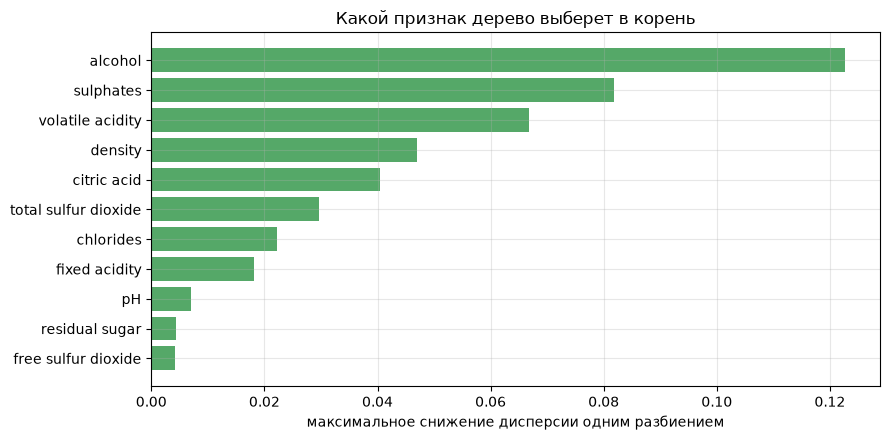

,снижение дисперсии
alcohol,0.1227
sulphates,0.0818
volatile acidity,0.0668
density,0.0469
citric acid,0.0405
total sulfur dioxide,0.0296
chlorides,0.0221
fixed acidity,0.0182
pH,0.0070
residual sugar,0.0043


In [19]:
# Лучший порог для каждого признака
gains = {}
for col in features:
    vals = np.unique(X_train[col])
    g = [var_root - weighted_var(col, t) for t in vals]
    g = [v for v in g if not np.isnan(v)]
    gains[col] = max(g) if g else np.nan

gains = pd.Series(gains).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(gains.index[::-1], gains.values[::-1], color="#55A868")
ax.set_xlabel("максимальное снижение дисперсии одним разбиением")
ax.set_title("Какой признак дерево выберет в корень")
plt.tight_layout(); plt.show()

gains.round(5).to_frame("снижение дисперсии")

Победил `alcohol` со снижением 0.123 при пороге 10.53 — ровно тот признак, который на прошлом занятии
оказался лидером и по корреляции, и по стандартизованному коэффициенту.
Проверим, что `sklearn` построит то же самое.

In [20]:
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text

tree = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train)
print(export_text(tree, feature_names=features, decimals=2))

|--- alcohol <= 10.53
|   |--- volatile acidity <= 0.31
|   |   |--- value: [6.06]
|   |--- volatile acidity >  0.31
|   |   |--- value: [5.31]
|--- alcohol >  10.53
|   |--- sulphates <= 0.64
|   |   |--- value: [5.75]
|   |--- sulphates >  0.64
|   |   |--- value: [6.33]



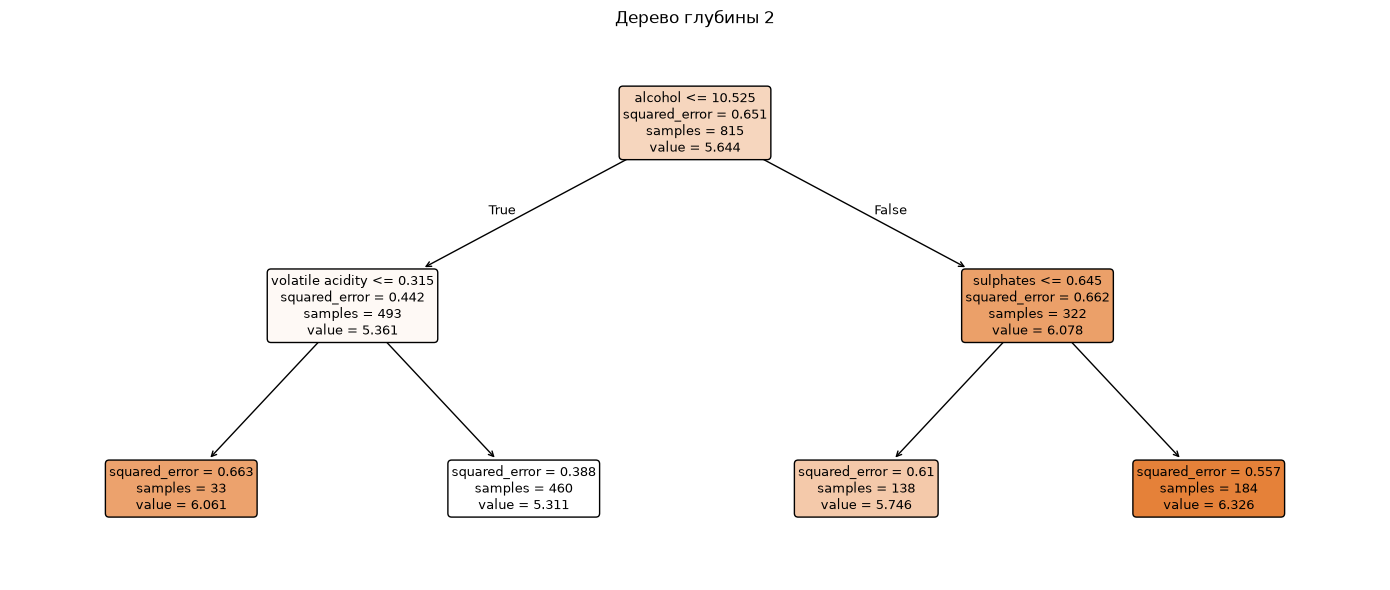

In [21]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train),
          feature_names=features, filled=True, rounded=True, fontsize=9, ax=ax)
plt.title("Дерево глубины 2")
plt.tight_layout(); plt.show()

Дерево читается как набор правил: сначала порог по крепости, затем по летучей кислотности
в одной ветке и по сульфатам в другой. Это главное практическое отличие от линейной
модели — результат можно пересказать словами.

Дереву не нужна стандартизация: разбиение сравнивает признак с порогом, а порядок значений
не меняется ни при каком монотонном преобразовании.

In [22]:
t_raw = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE).fit(X_train, y_train)
t_scaled = make_pipeline(StandardScaler(),
                         DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)).fit(X_train, y_train)

X_log, X_val_log = X_train.copy(), X_val.copy()
X_log["alcohol"] = np.log(X_log["alcohol"])
X_val_log["alcohol"] = np.log(X_val_log["alcohol"])
t_log = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE).fit(X_log, y_train)

print("дерево:")
print(f"  сырые признаки     {mean_absolute_error(y_val, t_raw.predict(X_val)):.6f}")
print(f"  StandardScaler     {mean_absolute_error(y_val, t_scaled.predict(X_val)):.6f}")
print(f"  log(alcohol)       {mean_absolute_error(y_val, t_log.predict(X_val_log)):.6f}")
print("линейная регрессия:")
print(f"  сырые признаки     {mean_absolute_error(y_val, LinearRegression().fit(X_train, y_train).predict(X_val)):.6f}")
print(f"  log(alcohol)       {mean_absolute_error(y_val, LinearRegression().fit(X_log, y_train).predict(X_val_log)):.6f}")

дерево:
  сырые признаки     0.568048
  StandardScaler     0.568048
  log(alcohol)       0.568048
линейная регрессия:
  сырые признаки     0.536972
  log(alcohol)       0.535813


#### Алгоритм построения

Мы разобрали один узел. Всё дерево строится повторением этого шага вглубь:

> **build**(множество объектов $R$):
> 1. если сработал критерий останова — создать лист со значением $c^{*}(R)$ и выйти;
> 2. для каждого признака $j$ и каждого допустимого порога $t$ посчитать $Q(j, t)$;
> 3. выбрать пару $(j^{*}, t^{*})$ с минимальным $Q$;
> 4. если снижение $Q$ не оправдывает разбиения — создать лист и выйти (критерий останова);
> 5. разделить $R$ на $R_{\text{left}} = \{i \in R: x_{ij^{*}} \le t^{*}\}$ и $R_{\text{right}}$;
> 6. рекурсивно вызвать **build** для каждой половины.

Дерево вызывается от корня со всей обучающей выборкой. Три места в этой схеме стоит
разобрать подробнее.

**Значение в листе.** Константа $c^{*}(R)$ выбирается так, чтобы минимизировать потери
внутри области. Это та же задача, что в первом семинаре решалась для константной модели:
при квадратичных потерях оптимум — среднее по области, при абсолютных — медиана.
В `sklearn` за это отвечает `criterion`, и он меняет не только значения в листьях,
но и сами пороги.

In [23]:
from sklearn.tree import DecisionTreeRegressor

for crit in ("squared_error", "absolute_error"):
    t = DecisionTreeRegressor(criterion=crit, max_depth=1, random_state=RANDOM_STATE).fit(X_train, y_train)
    j, thr = features[t.tree_.feature[0]], t.tree_.threshold[0]
    left, right = t.tree_.value.ravel()[1:]
    mask = X_train[j].values <= thr
    print(f"criterion={crit}")
    print(f"  корень: {j} <= {thr:.2f}")
    print(f"  листья дерева:  слева {left:.3f}   справа {right:.3f}")
    print(f"  среднее:        слева {y_train.values[mask].mean():.3f}   справа {y_train.values[~mask].mean():.3f}")
    print(f"  медиана:        слева {np.median(y_train.values[mask]):.1f}     справа {np.median(y_train.values[~mask]):.1f}\n")

criterion=squared_error
  корень: alcohol <= 10.53
  листья дерева:  слева 5.361   справа 6.078
  среднее:        слева 5.361   справа 6.078
  медиана:        слева 5.0     справа 6.0

criterion=absolute_error
  корень: alcohol <= 10.02
  листья дерева:  слева 5.000   справа 6.000
  среднее:        слева 5.280   справа 5.961
  медиана:        слева 5.0     справа 6.0



При `squared_error` в листьях стоят средние (5.361 и 6.078), при `absolute_error` — медианы
(5 и 6), и порог в корне сдвигается с 10.53 на 10.02. Выбор функции потерь здесь работает
точно так же, как в разделе про константную модель на прошлом занятии.

**Перебор порогов.** Значение $Q(j, t)$ меняется только когда порог переходит через
наблюдаемое значение признака, поэтому перебирать непрерывный $t$ не нужно: достаточно
середин между соседними различными значениями. Их число конечно и заранее известно.

In [24]:
candidates = {col: len(np.unique(X_train[col])) - 1 for col in features}
total = sum(candidates.values())

print(f"число наблюдений в корне: {len(X_train)}")
print(f"кандидатов-порогов по всем признакам: {total}\n")
print(pd.Series(candidates).sort_values(ascending=False).to_frame("порогов").head(5).to_string())

число наблюдений в корне: 815
кандидатов-порогов по всем признакам: 1229

                      порогов
density                   334
chlorides                 128
total sulfur dioxide      128
volatile acidity          127
fixed acidity              85


**Почему жадно.** На шаге 3 выбирается лучшее разбиение здесь и сейчас, без учёта того,
что будет ниже. Поиск дерева, оптимального целиком, —
NP-трудная задача, и переборный вариант неприменим уже на наших размерах. Разбиение, которое само по себе слабое, могло бы открыть
хорошее продолжение, но дерево его не выберет. И наоборот: малое изменение данных
меняет выбор в одном узле, а вместе с ним и всё поддерево под ним.

### 3.2 Критерии останова

Если дерево растить без ограничений, оно доведёт каждый лист до одного объекта
и запомнит выборку. Ограничить рост можно с разных сторон:

| Параметр | Что ограничивает |
|---|---|
| `max_depth` | число последовательных разбиений |
| `min_samples_split` | сколько объектов должно быть в узле, чтобы продолжать разбиение |
| `min_samples_leaf` | сколько объектов обязано остаться в каждом листе |
| `max_leaf_nodes` | общее число листьев |
| `min_impurity_decrease` | минимальное снижение неоднородности (в регрессии — дисперсии) |

Дерево без ограничений доводит обучающую ошибку до нуля: 249 листьев, train MAE $=0$.
На валидации оно даёт 0.629 — хуже любого дерева глубины не больше шести.

Кривая по глубине:

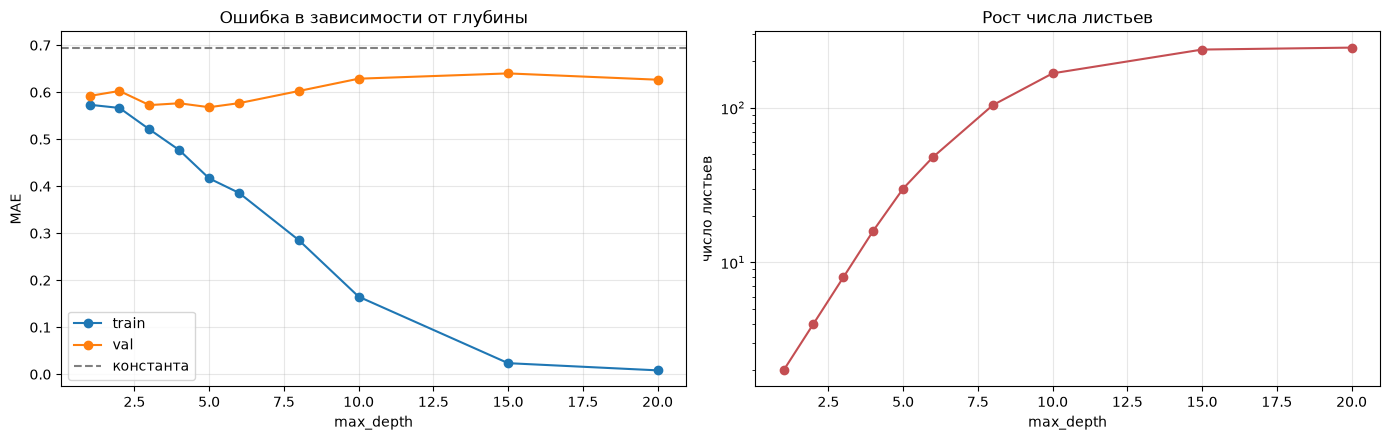

лучшая глубина по валидации: 5, val MAE 0.5680


In [25]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
tr, va, lv = [], [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr.append(mean_absolute_error(y_train, t.predict(X_train)))
    va.append(mean_absolute_error(y_val, t.predict(X_val)))
    lv.append(t.get_n_leaves())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(depths, tr, "o-", label="train")
ax1.plot(depths, va, "o-", label="val")
ax1.axhline(baseline_mae, color="gray", ls="--", label="константа")
ax1.set_xlabel("max_depth"); ax1.set_ylabel("MAE")
ax1.set_title("Ошибка в зависимости от глубины"); ax1.legend()

ax2.plot(depths, lv, "o-", color="#C44E52")
ax2.set_xlabel("max_depth"); ax2.set_ylabel("число листьев")
ax2.set_yscale("log")
ax2.set_title("Рост числа листьев")

plt.tight_layout(); plt.show()

print(f"лучшая глубина по валидации: {depths[int(np.argmin(va))]}, val MAE {min(va):.4f}")

Разрыв между кривыми — та же картина переобучения, что в прошлый раз у полиномиальной
регрессии, но здесь сложность измеряется числом листьев. Оно примерно удваивается с каждым
уровнем, пока в узлах есть что делить (2, 4, 8, 16, 30, 48), а затем выходит
на насыщение: делить становится нечего.

Отдельное свойство: дерево кусочно-постоянно, поэтому различных предсказаний у него
не больше, чем листьев.

In [26]:
for d in (2, 3, 5, None):
    t = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    preds = t.predict(X_val)
    print(f"max_depth={str(d):4s} листьев {t.get_n_leaves():4d}  различных предсказаний на val: {len(np.unique(preds)):3d}")

max_depth=2    листьев    4  различных предсказаний на val:   4
max_depth=3    листьев    8  различных предсказаний на val:   8
max_depth=5    листьев   30  различных предсказаний на val:  21
max_depth=None листьев  249  различных предсказаний на val:   6


У полного дерева различных предсказаний всего шесть — столько же, сколько значений
принимает `quality`. Причина не в том, что в каждом листе по одному объекту: листьев
249 на 815 объектов, и ровно один объект лежит только в 100 из них. Дерево растёт,
пока лист не станет **однородным**, то есть пока все попавшие в него объекты не
получат одно и то же значение `quality`. Среднее по такому листу равно этому самому
значению, а значений всего шесть.

Отсюда и нулевая ошибка на обучении, и аналогия с kNN при $k=1$: разница лишь в том,
что дерево запоминает не отдельные объекты, а однородные по ответу группы.

### 3.3 Неустойчивость к выборке

У дерева есть свойство: небольшое изменение
обучающей выборки может перестроить его целиком. Разбиения выбираются жадно, поэтому
смена признака в одном узле меняет все его поддеревья.

Проверим на бутстрэп-выборках: берём из train выборку того же размера с возвращением
и обучаем дерево заново (сравнение условно).

In [27]:
rng = np.random.default_rng(0)
B = 50
roots, thresholds, tree_preds, lin_preds = [], [], [], []

for b in range(B):
    idx = rng.integers(0, len(X_train), len(X_train))
    Xb, yb_ = X_train.iloc[idx], y_train.iloc[idx]

    t = DecisionTreeRegressor(random_state=0).fit(Xb, yb_)
    roots.append(features[t.tree_.feature[0]])
    thresholds.append(t.tree_.threshold[0])
    tree_preds.append(t.predict(X_val))

    lin_preds.append(LinearRegression().fit(Xb, yb_).predict(X_val))

tree_preds, lin_preds = np.array(tree_preds), np.array(lin_preds)

print("признак в корне по 50 выборкам:")
print(pd.Series(roots).value_counts().to_string())
root_mode = pd.Series(roots).mode()[0]
thr_mode = [t for t, r in zip(thresholds, roots) if r == root_mode]
print(f"\nпорог в корне (только деревья с {root_mode} в корне): "
      f"от {min(thr_mode):.2f} до {max(thr_mode):.2f}")
print(f"\nразброс предсказания одного объекта (среднее std по val):")
print(f"  дерево              {tree_preds.std(axis=0).mean():.4f}")
print(f"  линейная регрессия  {lin_preds.std(axis=0).mean():.4f}")

признак в корне по 50 выборкам:
alcohol      49
sulphates     1

порог в корне (только деревья с alcohol в корне): от 9.95 до 11.55

разброс предсказания одного объекта (среднее std по val):
  дерево              0.6349
  линейная регрессия  0.0868


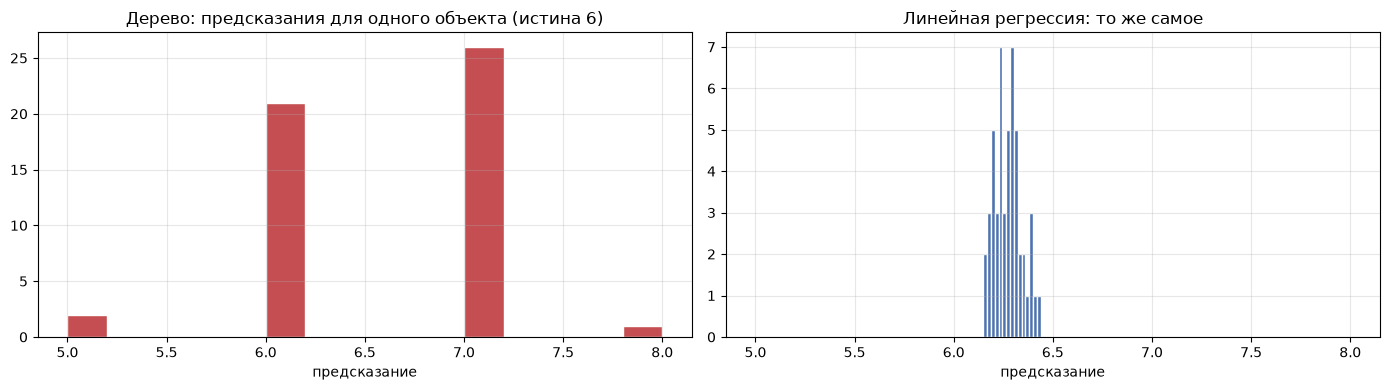

In [28]:
obj = 0
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
axes[0].hist(tree_preds[:, obj], bins=15, color="#C44E52", edgecolor="white")
axes[0].set_title(f"Дерево: предсказания для одного объекта (истина {y_val.iloc[obj]})")
axes[0].set_xlabel("предсказание")
axes[1].hist(lin_preds[:, obj], bins=15, color="#4C72B0", edgecolor="white")
axes[1].set_title("Линейная регрессия: то же самое")
axes[1].set_xlabel("предсказание")
plt.tight_layout(); plt.show()

Разброс предсказаний у дерева примерно в семь раз больше, чем у линейной регрессии.
Признак в корне в основном устойчив, но порог гуляет, а ниже по дереву расхождения
накапливаются.

Это и есть **высокая дисперсия модели**: дерево чувствительно не к сигналу, а к тому,
какие именно объекты попали в выборку.

## 4. Ансамбли

### 4.1 Идея

Неустойчивость дерева можно превратить в преимущество. Пусть есть $B$ моделей с
ошибками, имеющими одинаковую дисперсию $\sigma^2$ и попарную корреляцию $\rho$.
Дисперсия их среднего равна

$$\mathbb{V}\mathrm{ar}\left(\frac{1}{B}\sum_{b=1}^{B} f_b\right)
= \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2.$$

При $B \to \infty$ второе слагаемое исчезает, и остаётся $\rho\sigma^2$. Отсюда два вывода:
усреднение снижает дисперсию, и тем сильнее, чем менее скоррелированы модели.
Смещение при усреднении не меняется, поэтому в ансамбль собирают модели с малым смещением
и большой дисперсией — глубокие деревья подходят идеально.

А чему будет равно мат. ожидание?

$$\mathbb{E}\left(\frac{1}{B}\sum_{b=1}^{B} f_b\right)
=\mathbb{E}(f_b)$$

**Бэггинг** (bootstrap aggregating) обучает каждую модель на своей бутстрэп-выборке.
Мы это уже сделали в разделе 3.3 — осталось усреднить предсказания.

In [29]:
single = np.mean([mean_absolute_error(y_val, p) for p in tree_preds])
averaged = mean_absolute_error(y_val, tree_preds.mean(axis=0))

# лучшее одиночное дерево подбираем по валидации, а не берём параметр с потолка
msl_grid = [1, 2, 5, 10, 20, 30, 40, 50, 60, 80, 100]
msl_scores = {m: mean_absolute_error(
    y_val, DecisionTreeRegressor(min_samples_leaf=m, random_state=RANDOM_STATE)
           .fit(X_train, y_train).predict(X_val)) for m in msl_grid}
best_msl = min(msl_scores, key=msl_scores.get)
best_single = DecisionTreeRegressor(min_samples_leaf=best_msl, random_state=RANDOM_STATE).fit(X_train, y_train)
best_single_mae = msl_scores[best_msl]

print(f"среднее MAE одного дерева из 50:        {single:.4f}")
print(f"MAE усреднённого предсказания:          {averaged:.4f}")
print(f"лучшее одиночное дерево (min_samples_leaf={best_msl}, "
      f"листьев {best_single.get_n_leaves()}):  {best_single_mae:.4f}")
print(f"линейная регрессия:                     {linear_mae:.4f}")

среднее MAE одного дерева из 50:        0.6579
MAE усреднённого предсказания:          0.5318
лучшее одиночное дерево (min_samples_leaf=50, листьев 13):  0.5497
линейная регрессия:                     0.5370


Усреднение тех же самых деревьев даёт 0.532 против 0.550 у лучшего одиночного дерева
(13 листьев при `min_samples_leaf=50`). При этом каждое дерево в отдельности работает
плохо: в среднем 0.658, то есть немногим лучше константы. Ошибки деревьев частично
независимы и при сложении гасят друг друга.

С линейной регрессией (0.537) разница составляет 0.005 — это в четыре раза меньше
шума разбиения, и по одной валидационной выборке такой вывод делать нельзя.
Отложим сравнение до раздела 5.

### 4.2 Бэггинг и случайный лес

<center>
<img src="https://contest.yandex.ru/tracks/ml/_assets/supervised-learning/ensembles-in-machine-learning/image_1_248dc7a6ed-framed.svg" width="70%" align="center">
</center>

У бэггинга деревья всё же похожи: они обучены на пересекающихся выборках и в корне
почти всегда выбирают `alcohol`. **Случайный лес** дополнительно декоррелирует их,
разрешая в каждом узле перебирать только случайное подмножество признаков
(`max_features`).

#### Алгоритм случайного леса

> **build**(обучающая выборка размера $n$, число деревьев $B$, число признаков $m$):
> 1. для $b = 1, \dots, B$:
>    1. взять бутстрэп-выборку $X_b$: $n$ объектов из обучающей **с возвращением**;
>    2. вырастить дерево $f_b$ на $X_b$ **без ограничений**, но в каждом узле
>       перебирать не все $p$ признаков, а случайные $m$ из них;
> 2. предсказание — среднее: $\;\hat{f}(\mathbf{x}) = \dfrac{1}{B}\sum_{b=1}^{B} f_b(\mathbf{x})$.

Отличие бэггинга — только в пункте 1.2: там в каждом узле перебираются все признаки,
то есть $m = p$. Источников случайности, таким образом, два: выбор объектов и выбор
признаков, и второй есть только у леса.

**Что даёт бутстрэп.** Выборка с возвращением того же размера содержит не все исходные
объекты: какие-то попадают дважды и трижды, какие-то не попадают вовсе. Вероятность,
что конкретный объект не выбран ни одного раза, равна $(1 - 1/n)^n$, поэтому доля
различных объектов в дереве составляет

$$1 - \left(1 - \frac{1}{n}\right)^{n} \;\xrightarrow[n \to \infty]{}\; 1 - \frac{1}{e} \approx 0.632.$$

Грубо говоря, каждое дерево видит около 63% различных объектов — доля случайная,
и 0.632 это её предел при больших $n$. Получается, что деревья обучены на пересекающихся, но разных выборках. "Невидимые" (те, что не попали в конкретную выборку) объекты,
кстати, можно использовать для оценки качества без отдельной валидационной выборки —
это out-of-bag оценка.

**Почему деревья в лесу не ограничивают.** Из формулы раздела 4.1 усреднение снижает
дисперсию, но не смещение. Значит, в ансамбль нужно собирать модели с малым смещением,
пусть и с огромной дисперсией — то есть глубокие деревья. Поэтому в `sklearn` у леса
по умолчанию `max_depth=None` и `min_samples_leaf=1`: ограничивать рост здесь не нужно,
с дисперсией справится усреднение.

In [30]:
from sklearn.ensemble import RandomForestRegressor

defaults = RandomForestRegressor()
print("дефолты RandomForestRegressor:")
for p_ in ("n_estimators", "max_features", "max_depth", "min_samples_leaf", "bootstrap"):
    print(f"  {p_:18s} {getattr(defaults, p_)}")

дефолты RandomForestRegressor:
  n_estimators       100
  max_features       1.0
  max_depth          None
  min_samples_leaf   1
  bootstrap          True


Обратите внимание на `max_features=1.0` — это доля признаков, то есть **все** признаки.
Для регрессии случайный лес в `sklearn` по умолчанию вырождается в бэггинг;
случайность признаков надо включать руками. У классификатора дефолт другой,
`sqrt`, то есть $\sqrt{p}$ признаков в узле.

Поэтому «случайный лес» с настройками по умолчанию и есть бэггинг: расхождение
появится только тогда, когда `max_features` мы зададим руками.

Проверим напрямую, что декорреляция работает: посчитаем среднюю попарную корреляцию
предсказаний отдельных деревьев — ту самую $\rho$ из формулы для дисперсии среднего.

In [31]:
for mf, label in ((1.0, "max_features=1.0 (бэггинг)"), (4, "max_features=4")):
    forest_rho = RandomForestRegressor(n_estimators=50, max_features=mf,
                                       random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    P = np.array([t.predict(X_val.values) for t in forest_rho.estimators_])
    C = np.corrcoef(P)
    iu = np.triu_indices_from(C, k=1)
    print(f"{label:28s} rho = {C[iu].mean():.4f}   "
          f"ансамбль: val MAE {mean_absolute_error(y_val, P.mean(axis=0)):.4f}")

max_features=1.0 (бэггинг)   rho = 0.3637   ансамбль: val MAE 0.5306
max_features=4               rho = 0.3425   ансамбль: val MAE 0.5268


Ограничение признаков снижает корреляцию между деревьями с 0.364 до 0.343.
Величина $\rho$ здесь не абстракция из формулы, а измеримая
характеристика ансамбля: это она задаёт тот предел, ниже которого добавление
новых деревьев уже не опускает ошибку.

Ошибка ансамбля при этом сдвигается с 0.531 до 0.527. Направление согласуется
с формулой, но сам сдвиг на порядок меньше шума, так что измеримо здесь снижение
$\rho$, а не выигрыш в MAE.

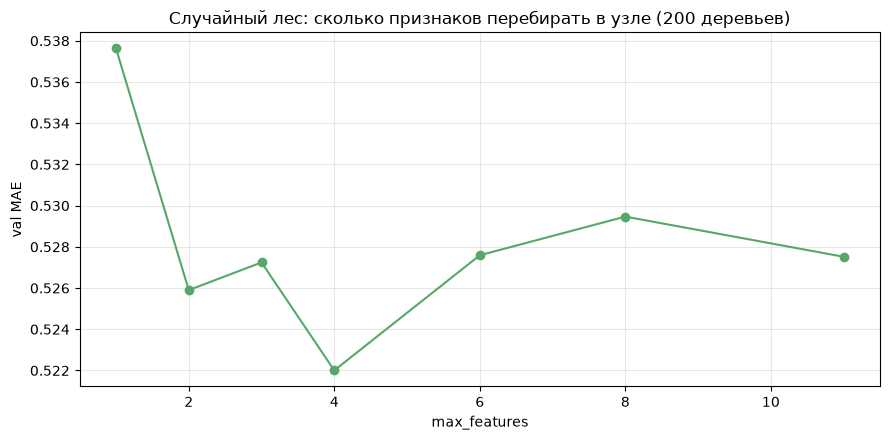

лучшее max_features: 4, val MAE 0.5220
max_features=11 (это бэггинг): val MAE 0.5275


In [32]:
mfs = [1, 2, 3, 4, 6, 8, 11]
sc = [mean_absolute_error(y_val, RandomForestRegressor(
        n_estimators=200, max_features=mf, random_state=RANDOM_STATE, n_jobs=-1)
        .fit(X_train, y_train).predict(X_val)) for mf in mfs]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mfs, sc, "o-", color="#55A868")
ax.set_xlabel("max_features")
ax.set_ylabel("val MAE")
ax.set_title("Случайный лес: сколько признаков перебирать в узле (200 деревьев)")
plt.tight_layout(); plt.show()

print(f"лучшее max_features: {mfs[int(np.argmin(sc))]}, val MAE {min(sc):.4f}")
print(f"max_features=11 (это бэггинг): val MAE {sc[-1]:.4f}")

`max_features=11` означает перебор всех признаков, то есть обычный бэггинг.
Содержательно ограничение признаков делает деревья по отдельности хуже, но менее
похожими друг на друга — ровно тот компромисс, который виден в формуле для дисперсии
среднего.

На наших данных компромисс почти не отражается на качестве: кривая плоская начиная
с `max_features=2`, и лучшее значение отличается от бэггинга на 0.006. Отчётливо
виден только провал при `max_features=1`, когда признак в узле фактически
не выбирается.

### 4.3 Важность признаков

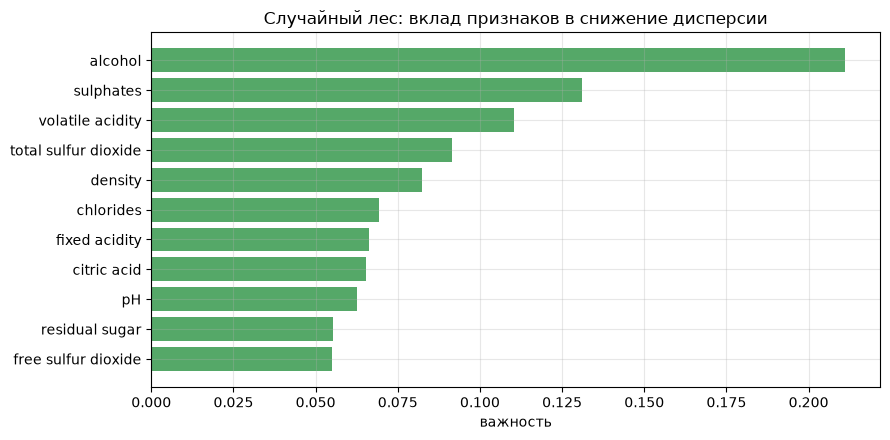

,"важность, %"
alcohol,21.1
sulphates,13.1
volatile acidity,11.0
total sulfur dioxide,9.1
density,8.2
chlorides,6.9
fixed acidity,6.6
citric acid,6.5
pH,6.2
residual sugar,5.5


In [33]:
rf = RandomForestRegressor(n_estimators=300, max_features=4,
                           random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=features).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp.values, color="#55A868")
ax.set_xlabel("важность")
ax.set_title("Случайный лес: вклад признаков в снижение дисперсии")
plt.tight_layout(); plt.show()

(imp.sort_values(ascending=False) * 100).round(1).to_frame("важность, %")

Лидируют те же `alcohol`, `sulphates` и `volatile acidity`. Но у такой важности есть
два дефекта. Она считается по обучающей выборке, поэтому награждает признак за участие
в разбиениях, даже если те подгоняли шум. И она смещена в сторону признаков с большим
числом уникальных значений: чем больше возможных порогов, тем больше шансов случайно
снизить дисперсию. Обратите внимание, что нулей в этом списке нет вовсе — вклад получили
все одиннадцать признаков.

#### Permutation importance

Другой подход измеряет важность через ущерб от порчи признака. Берём **отложенную**
выборку, случайно перемешиваем в ней значения одного признака (связь с целевой
переменной разрывается, распределение сохраняется) и смотрим, насколько выросла ошибка:

$$\mathrm{PI}_j = \frac{1}{R}\sum_{r=1}^{R}
\Big[ L\big(y,\, \hat{f}(X^{(j,r)}_{\text{perm}})\big) - L\big(y,\, \hat{f}(X)\big) \Big],$$

где $X^{(j,r)}_{\text{perm}}$ — выборка с перемешанным $j$-м признаком, $R$ — число повторов.
Метод не зависит от устройства модели (применим и к линейной регрессии, и к kNN),
а повторы дают оценку разброса.

In [34]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(rf, X_val, y_val, n_repeats=20,
                            scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1)

comparison = pd.DataFrame({
    "impurity": rf.feature_importances_,
    "permutation": pi.importances_mean,
    "разброс": pi.importances_std,
}, index=features).sort_values("permutation", ascending=False)

comparison["mean - 2*std"] = comparison["permutation"] - 2 * comparison["разброс"]
comparison.round(4)

,impurity,permutation,разброс,mean - 2*std
alcohol,0.2112,0.0987,0.0151,0.0685
sulphates,0.1311,0.0426,0.0108,0.0210
volatile acidity,0.1105,0.0308,0.0063,0.0183
total sulfur dioxide,0.0914,0.0143,0.0055,0.0033
density,0.0824,0.0108,0.0050,0.0007
chlorides,0.0692,0.0066,0.0028,0.0011
residual sugar,0.0552,0.0038,0.0021,-0.0005
citric acid,0.0653,0.0030,0.0028,-0.0027
pH,0.0625,0.0026,0.0035,-0.0043
free sulfur dioxide,0.0549,0.0025,0.0030,-0.0035


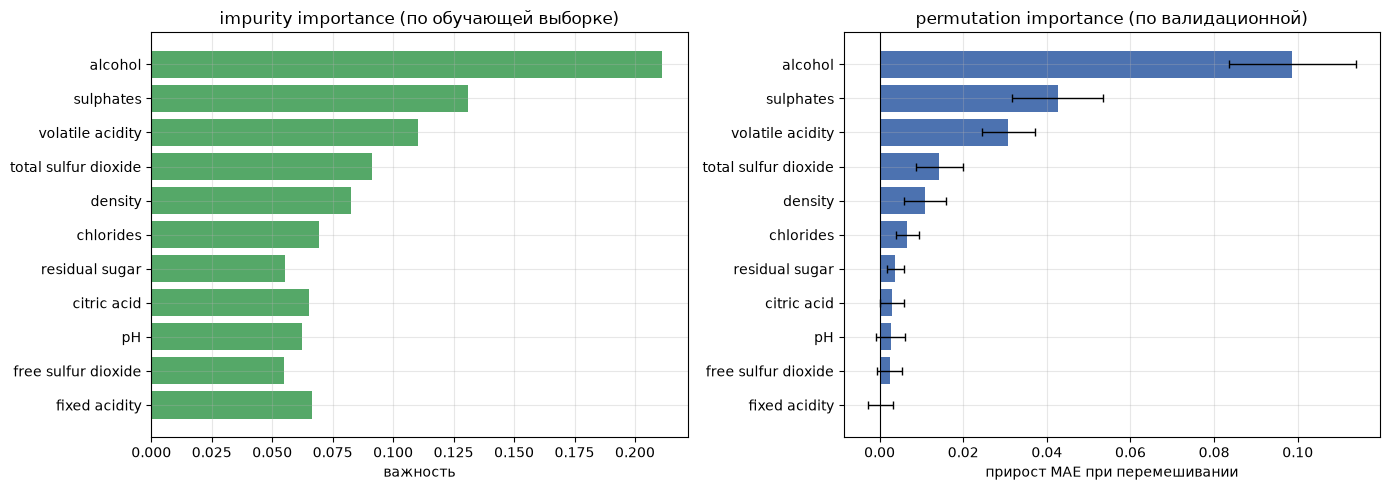

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = comparison.index[::-1]
axes[0].barh(order, comparison.loc[order, "impurity"], color="#55A868")
axes[0].set_xlabel("важность")
axes[0].set_title("impurity importance (по обучающей выборке)")

axes[1].barh(order, comparison.loc[order, "permutation"],
             xerr=comparison.loc[order, "разброс"], color="#4C72B0",
             error_kw={"lw": 1, "capsize": 3})
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("прирост MAE при перемешивании")
axes[1].set_title("permutation importance (по валидационной)")

plt.tight_layout(); plt.show()

Верхушка списка совпадает: `alcohol`, `sulphates`, `volatile acidity` важны по обеим мерам.
Расхождения начинаются ниже.

У пяти признаков из одиннадцати интервал «среднее минус два разброса» уходит в отрицательную
область, то есть их перемешивание не ухудшает предсказания сколько-нибудь надёжно.
При этом impurity importance даёт каждому из них по 5–7%.

Самый показательный случай — `fixed acidity`: по impurity он седьмой из одиннадцати,
а по перестановкам последний, с вкладом, неотличимым от нуля. На прошлом занятии у этого
признака был наибольший фактор инфляции дисперсии (VIF около 7.8): он почти полностью
восстанавливается по остальным. Дерево охотно использует его в разбиениях, но при порче
модель берёт ту же информацию из коррелированных признаков, и ошибка не растёт.

Это общее свойство: permutation importance отвечает на вопрос «насколько модели нужен
этот признак **при наличии остальных**», а не «насколько признак связан с целевой
переменной». У двух дублирующих друг друга признаков важность будет низкой у обоих,
хотя выбросить оба нельзя.

Ещё одна причина считать permutation importance на отложенной выборке, а не на обучающей:

In [36]:
for name, (Xs, ys) in {"train": (X_train, y_train), "val": (X_val, y_val)}.items():
    p = permutation_importance(rf, Xs, ys, n_repeats=10, scoring="neg_mean_absolute_error",
                               random_state=RANDOM_STATE, n_jobs=-1)
    s = pd.Series(p.importances_mean, index=features)
    print(f"{name:5s}: сумма вкладов {s.sum():.4f} | "
          f"alcohol {s['alcohol']:.4f} | fixed acidity {s['fixed acidity']:+.4f}")

train: сумма вкладов 1.2205 | alcohol 0.2770 | fixed acidity +0.0704
val  : сумма вкладов 0.2036 | alcohol 0.0929 | fixed acidity -0.0000


На обучающей выборке суммарная важность в шесть раз выше, а `fixed acidity` получает
заметный положительный вклад вместо нуля. Причина та же, что и у нулевой обучающей ошибки
переобученного дерева: лес частично запомнил обучающие объекты, и порча любого признака
мешает ему их воспроизвести. Про обобщение это ничего не говорит.

## 5. Итоги

Финальная проверка на тесте. Гиперпараметры всех моделей выбраны по валидации,
тест используется один раз.

In [37]:
from sklearn.ensemble import BaggingRegressor

models = {
    "константа (медиана)": None,
    "линейная регрессия":  LinearRegression(),
    f"kNN k={best_k} + scaler": make_pipeline(StandardScaler(), KNeighborsRegressor(best_k)),
    f"дерево min_samples_leaf={best_msl}":
        DecisionTreeRegressor(min_samples_leaf=best_msl, random_state=RANDOM_STATE),
    "бэггинг 300 деревьев": BaggingRegressor(DecisionTreeRegressor(random_state=RANDOM_STATE),
                                             n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "случайный лес 300": RandomForestRegressor(n_estimators=300, max_features=4,
                                               random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for name, m in models.items():
    if m is None:
        rows.append({"модель": name,
                     "val MAE": baseline_mae,
                     "test MAE": mean_absolute_error(y_test, np.full(len(y_test), y_train.median())),
                     "CV MAE": np.nan, "CV std": np.nan})
    else:
        m.fit(X_train, y_train)
        cv = -cross_val_score(m, X_train_full, y_train_full, cv=kf,
                              scoring="neg_mean_absolute_error")
        rows.append({"модель": name,
                     "val MAE": mean_absolute_error(y_val, m.predict(X_val)),
                     "test MAE": mean_absolute_error(y_test, m.predict(X_test)),
                     "CV MAE": cv.mean(), "CV std": cv.std()})

summary = pd.DataFrame(rows).set_index("модель")
summary

,val MAE,test MAE,CV MAE,CV std
модель,,,,
константа (медиана),0.6949,0.7022,NaN,NaN
линейная регрессия,0.5370,0.5060,0.5175,0.0180
kNN k=5 + scaler,0.5588,0.5191,0.5431,0.0302
дерево min_samples_leaf=50,0.5497,0.4934,0.5402,0.0193
бэггинг 300 деревьев,0.5256,0.4699,0.5062,0.0193
случайный лес 300,0.5221,0.4630,0.5055,0.0194


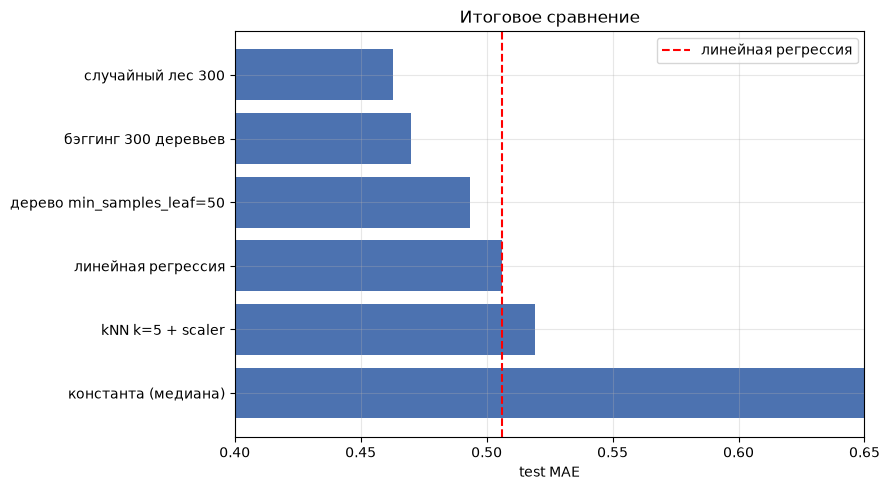

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))
s = summary["test MAE"].sort_values(ascending=False)
ax.barh(s.index, s.values, color="#4C72B0")
ax.axvline(summary.loc["линейная регрессия", "test MAE"], color="red", ls="--",
           label="линейная регрессия")
ax.set_xlim(0.40, 0.65)
ax.set_xlabel("test MAE")
ax.set_title("Итоговое сравнение")
ax.legend()
plt.tight_layout(); plt.show()